# Price–Volume–Mix (PVM) analysis in pandas

This notebook simulates two years of sales for a global consumer-security software portfolio and explains the revenue change with a **price–volume–mix bridge**, including **FX**, **new** and **discontinued** products.

**Effects (base period 0 → current period 1), on products sold in both periods:**

| Effect | Formula |
|---|---|
| Volume | $(Q_1 - Q_0)\cdot \dfrac{R_0}{Q_0}$ |
| Mix | $\sum p_0 q_1 - R_0 \cdot \dfrac{Q_1}{Q_0}$ |
| Price | $\sum (p_1 - p_0)\, q_1$ |

Plus three separate lines: **new products** (revenue in period 1 only), **discontinued products** (revenue in period 0 only) and **FX** (current revenue at current rates minus the same revenue at base-period rates).
Prices are **net** prices in EUR at **base-period FX**, so the price effect shows real local price changes and the FX line shows currency moves.

Sections:
1. Simulate the data
2. Explore it
3. The PVM function
4. Total bridge (waterfall)
5. PVM by market
6. Why granularity matters
7. Biggest price contributors
8. Takeaways

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.width", 120)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "font.size": 10.5,
})

COLORS = {
    "Volume": "#5B21B6", "Mix": "#17784F", "Price": "#B8166F",
    "New products": "#0E7490", "Discontinued": "#8A8F98", "FX": "#D97706",
    "base": "#3F3A52",
}
eur_k = mticker.FuncFormatter(lambda v, _: f"€{v/1e3:,.0f}k")
eur_m = mticker.FuncFormatter(lambda v, _: f"€{v/1e6:,.1f}M")

## 1. Simulate the data

Assumptions built into the simulation, so we know what the analysis *should* find:

- **Annual Price Review:** local prices rise in every market (+4% to +35%), most in high-inflation Turkey and Brazil.
- **FX:** several currencies weaken against the euro (TRY, BRL, INR, USD), so EUR revenue gets an FX headwind.
- **Mix:** customers move from Standard to Premium; the cheap standalone *Password Manager* is discontinued; a new *Premium Family* plan launches.
- **Channels:** more sales through Mobile (lower net price after app-store fees), fewer through Retail.
- **Volume:** strong growth in India and Brazil, decline in Turkey and the UK.

Each row is a SKU = market × product × channel, with units and **net** revenue in local currency (after VAT, channel fees and discounts).

In [2]:
rng = np.random.default_rng(2026)

markets = pd.DataFrame({
    "market":   ["DE", "US", "UK", "BR", "TR", "IN"],
    "currency": ["EUR", "USD", "GBP", "BRL", "TRY", "INR"],
    "fx_FY2025": [1.00, 1.08, 0.86, 5.60, 35.0, 90.0],   # local currency per 1 EUR
    "fx_FY2026": [1.00, 1.15, 0.85, 6.30, 42.0, 97.0],
    "ppp":       [1.00, 1.00, 1.00, 0.60, 0.50, 0.40],   # local affordability factor
    "base_units": [120_000, 200_000, 80_000, 90_000, 60_000, 110_000],
    "vol_growth": [0.00, 0.03, -0.02, 0.10, -0.05, 0.18],
    "price_increase": [0.05, 0.06, 0.04, 0.12, 0.35, 0.08],
})

products = pd.DataFrame({
    "product":   ["Standard", "Plus", "Premium", "VPN", "Password Manager", "Premium Family"],
    "segment":   ["Core", "Core", "Core", "Standalone", "Standalone", "Core"],
    "list_eur":  [35, 50, 65, 30, 15, 90],
    "share_FY2025": [0.40, 0.25, 0.15, 0.12, 0.08, 0.00],
    "unit_change":  [-0.10, 0.05, 0.25, 0.15, -1.00, np.nan],   # Password Manager discontinued
})

channels = pd.DataFrame({
    "channel": ["Web", "Mobile", "Retail"],
    "net_factor": [0.80, 0.68, 0.60],    # share of gross price kept after VAT, fees, partner margin
    "share": [0.50, 0.30, 0.20],
    "unit_change": [0.02, 0.20, -0.15],
})

grid = (markets.merge(products, how="cross").merge(channels, how="cross", suffixes=("", "_ch")))

rows = []
for period in ["FY2025", "FY2026"]:
    d = grid.copy()
    d["period"] = period
    # local net price per unit
    base_local = d["list_eur"] * d["fx_FY2025"] * d["ppp"] * d["net_factor"]
    uplift = 1 + d["price_increase"] if period == "FY2026" else 1.0
    d["net_price_local"] = (base_local * uplift * rng.normal(1, 0.008, len(d))).round(2)
    # units
    units0 = d["base_units"] * d["share_FY2025"] * d["share"]
    if period == "FY2025":
        units = units0
    else:
        prod_factor = 1 + d["unit_change"].fillna(0)
        units = units0 * (1 + d["vol_growth"]) * prod_factor * (1 + d["unit_change_ch"])
        # new product: Premium Family ≈ 18% of Premium units in each market × channel
        prem = d["base_units"] * 0.15 * d["share"] * (1 + d["vol_growth"]) * 1.25 * (1 + d["unit_change_ch"])
        units = np.where(d["product"] == "Premium Family", prem * 0.18, units)
    d["units"] = np.round(units * rng.lognormal(0, 0.04, len(d))).astype(int)
    d["fx"] = d[f"fx_{period}"]
    rows.append(d)

sales = pd.concat(rows, ignore_index=True)
sales = sales[sales["units"] > 0].copy()
sales["net_revenue_local"] = sales["units"] * sales["net_price_local"]
fx_base = sales["market"].map(markets.set_index("market")["fx_FY2025"])
sales["revenue_eur"] = sales["net_revenue_local"] / sales["fx"]           # at actual FX of the period
sales["revenue_eur_base_fx"] = sales["net_revenue_local"] / fx_base       # at FY2025 FX (constant currency)

sales = sales[["period", "market", "currency", "segment", "product", "channel",
               "units", "net_price_local", "net_revenue_local", "fx",
               "revenue_eur", "revenue_eur_base_fx"]]
sales.head(8)

,period,market,currency,segment,product,channel,units,net_price_local,net_revenue_local,fx,revenue_eur,revenue_eur_base_fx
0,FY2025,DE,EUR,Core,Standard,Web,24472,27.82,"680,811.04",1.00,"680,811.04","680,811.04"
1,FY2025,DE,EUR,Core,Standard,Mobile,15077,23.85,"359,586.45",1.00,"359,586.45","359,586.45"
2,FY2025,DE,EUR,Core,Standard,Retail,9297,20.68,"192,261.96",1.00,"192,261.96","192,261.96"
3,FY2025,DE,EUR,Core,Plus,Web,13688,40.45,"553,679.60",1.00,"553,679.60","553,679.60"
4,FY2025,DE,EUR,Core,Plus,Mobile,9041,34.17,"308,930.97",1.00,"308,930.97","308,930.97"
5,FY2025,DE,EUR,Core,Plus,Retail,5855,29.93,"175,240.15",1.00,"175,240.15","175,240.15"
6,FY2025,DE,EUR,Core,Premium,Web,8990,51.87,"466,311.30",1.00,"466,311.30","466,311.30"
7,FY2025,DE,EUR,Core,Premium,Mobile,5772,44.31,"255,757.32",1.00,"255,757.32","255,757.32"


## 2. Explore the data

In [3]:
summary = (sales.groupby("period")
           .agg(units=("units", "sum"),
                revenue_eur=("revenue_eur", "sum"),
                revenue_eur_const_fx=("revenue_eur_base_fx", "sum")))
summary["avg_net_price_eur"] = summary["revenue_eur"] / summary["units"]
summary

,units,revenue_eur,revenue_eur_const_fx,avg_net_price_eur
period,,,,
FY2025,663432,"15,698,833.94","15,698,833.94",23.66
FY2026,707409,"18,964,844.27","19,996,865.61",26.81


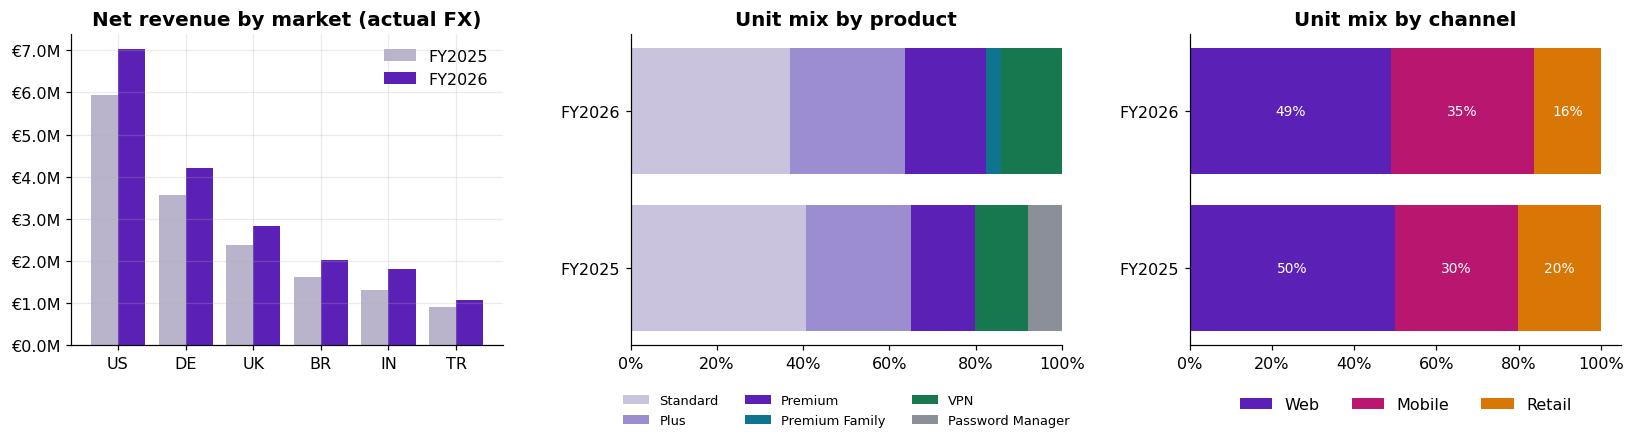

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# revenue by market
m = sales.pivot_table(index="market", columns="period", values="revenue_eur", aggfunc="sum")
m = m.sort_values("FY2025", ascending=False)
x = np.arange(len(m))
axes[0].bar(x - 0.2, m["FY2025"], 0.4, label="FY2025", color="#B9B3CC")
axes[0].bar(x + 0.2, m["FY2026"], 0.4, label="FY2026", color=COLORS["Volume"])
axes[0].set_xticks(x, m.index); axes[0].yaxis.set_major_formatter(eur_m)
axes[0].set_title("Net revenue by market (actual FX)"); axes[0].legend(frameon=False)

# product mix of units
pm = sales.pivot_table(index="period", columns="product", values="units", aggfunc="sum").fillna(0)
pm = pm.div(pm.sum(axis=1), axis=0)
order = ["Standard", "Plus", "Premium", "Premium Family", "VPN", "Password Manager"]
pal = ["#C9C3DD", "#9C8CD0", "#5B21B6", "#0E7490", "#17784F", "#8A8F98"]
left = np.zeros(len(pm))
for prod, col in zip(order, pal):
    axes[1].barh(pm.index, pm[prod], left=left, color=col, label=prod)
    left += pm[prod].values
axes[1].xaxis.set_major_formatter(mticker.PercentFormatter(1)); axes[1].set_title("Unit mix by product")
axes[1].legend(frameon=False, fontsize=8.5, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
axes[1].grid(False)

# channel mix of units
cm = sales.pivot_table(index="period", columns="channel", values="units", aggfunc="sum")
cm = cm.div(cm.sum(axis=1), axis=0)[["Web", "Mobile", "Retail"]]
left = np.zeros(len(cm))
for ch, col in zip(cm.columns, ["#5B21B6", "#B8166F", "#D97706"]):
    axes[2].barh(cm.index, cm[ch], left=left, color=col, label=ch)
    for i, v in enumerate(cm[ch]):
        axes[2].text(left[i] + v / 2, i, f"{v:.0%}", ha="center", va="center", color="white", fontsize=9)
    left += cm[ch].values
axes[2].xaxis.set_major_formatter(mticker.PercentFormatter(1)); axes[2].set_title("Unit mix by channel")
axes[2].legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.12)); axes[2].grid(False)

fig.tight_layout()
plt.show()

## 3. The PVM function

`pvm(df, keys)` aggregates the data to the level given by `keys` (the level at which **mix** is measured), splits items into continuing, new and discontinued, and returns all effects plus a reconciliation check.

In [5]:
def prepare(df, keys, base="FY2025", curr="FY2026"):
    # One row per item with base and current units / revenue.
    g = (df.groupby(["period"] + keys, as_index=False)
           .agg(units=("units", "sum"),
                rev_actual=("revenue_eur", "sum"),
                rev_const=("revenue_eur_base_fx", "sum")))
    b = g[g["period"] == base].set_index(keys)
    c = g[g["period"] == curr].set_index(keys)
    t = pd.DataFrame(index=b.index.union(c.index))
    t["q0"] = b["units"]
    t["r0"] = b["rev_const"]          # base period: actual FX = base FX
    t["q1"] = c["units"]
    t["r1_const"] = c["rev_const"]    # current period at base FX
    t["r1_actual"] = c["rev_actual"]  # current period at current FX
    t = t.fillna(0)
    t["status"] = np.select([(t.q0 > 0) & (t.q1 > 0), t.q1 > 0], ["continuing", "new"], "discontinued")
    return t


def pvm(df, keys, base="FY2025", curr="FY2026"):
    t = prepare(df, keys, base, curr)
    c = t[t["status"] == "continuing"].copy()
    c["p0"] = c["r0"] / c["q0"]
    c["p1"] = c["r1_const"] / c["q1"]

    Q0, Q1, R0 = c["q0"].sum(), c["q1"].sum(), c["r0"].sum()
    volume = (Q1 - Q0) * R0 / Q0
    mix = (c["p0"] * c["q1"]).sum() - R0 * Q1 / Q0
    price = ((c["p1"] - c["p0"]) * c["q1"]).sum()
    new = t.loc[t["status"] == "new", "r1_const"].sum()
    disc = -t.loc[t["status"] == "discontinued", "r0"].sum()
    fx = t["r1_actual"].sum() - t["r1_const"].sum()

    start, end = t["r0"].sum(), t["r1_actual"].sum()
    effects = pd.Series({"Volume": volume, "Mix": mix, "Price": price,
                         "New products": new, "Discontinued": disc, "FX": fx})
    check = effects.sum() - (end - start)
    assert abs(check) < 1e-6 * max(1, abs(end)), f"Bridge does not reconcile: {check}"
    return {"start": start, "end": end, "effects": effects, "items": c, "table": t}


res = pvm(sales, ["market", "product", "channel"])
print(f"FY2025 revenue: €{res['start']:,.0f}")
print(f"FY2026 revenue: €{res['end']:,.0f}   change: €{res['end'] - res['start']:+,.0f} "
      f"({res['end'] / res['start'] - 1:+.1%})")
res["effects"].to_frame("effect, €").assign(**{"share of change": lambda x: x["effect, €"] / (res["end"] - res["start"])})

FY2025 revenue: €15,698,834
FY2026 revenue: €18,964,844   change: €+3,266,010 (+20.8%)


,"effect, €",share of change
Volume,"1,782,126.35",0.55
Mix,"244,073.09",0.07
Price,"1,367,402.08",0.42
New products,"1,356,465.73",0.42
Discontinued,"-452,035.58",-0.14
FX,"-1,032,021.34",-0.32


## 4. Total bridge: waterfall chart

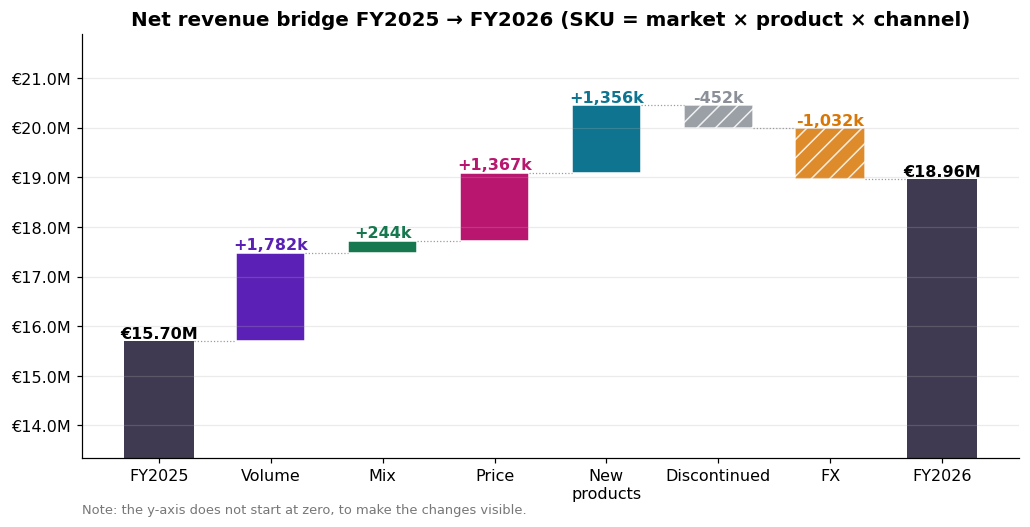

In [6]:
def waterfall(start, effects, end, title, labels=("FY2025", "FY2026"), ax=None):
    ax = ax or plt.subplots(figsize=(11, 5))[1]
    names = [labels[0]] + list(effects.index) + [labels[1]]
    tick_names = [n.replace(" ", "\n") for n in names]
    path = np.cumsum([start] + list(effects.values))
    vals = [start] + list(effects.values) + [end]
    running = start
    for i, (n, v) in enumerate(zip(names, vals)):
        if i == 0 or i == len(vals) - 1:
            ax.bar(i, v, color=COLORS["base"], width=0.62)
            ax.text(i, v, f"€{v/1e6:,.2f}M", ha="center", va="bottom", fontweight="bold")
        else:
            bottom = running if v >= 0 else running + v
            ax.bar(i, abs(v), bottom=bottom, color=COLORS[n], width=0.62, alpha=1 if v >= 0 else 0.85,
                   hatch=None if v >= 0 else "//", edgecolor="white")
            ax.plot([i - 1 + 0.31, i - 0.31], [running, running], color="#999", lw=0.8, ls=":")
            running += v
            ax.text(i, max(running, running - v), f"{v/1e3:+,.0f}k", ha="center", va="bottom",
                    color=COLORS[n], fontweight="bold")
    ax.plot([len(vals) - 2 + 0.31, len(vals) - 1 - 0.31], [running, running], color="#999", lw=0.8, ls=":")
    ax.set_xticks(range(len(names)), tick_names)
    ax.yaxis.set_major_formatter(eur_m)
    lo = min(path.min(), end) * 0.85
    ax.set_ylim(lo, max(path.max(), end) * 1.07)
    ax.text(0.0, -0.13, "Note: the y-axis does not start at zero, to make the changes visible.",
            transform=ax.transAxes, fontsize=8.5, color="#777")
    ax.set_title(title)
    ax.grid(axis="x", visible=False)
    return ax

waterfall(res["start"], res["effects"], res["end"],
          "Net revenue bridge FY2025 → FY2026 (SKU = market × product × channel)")
plt.show()

**How to read it:** the price effect is the Annual Price Review measured in constant currency; the FX bar is the currency headwind. Mix combines the move to Premium (positive) and the move to Mobile, which has a lower net price after app-store fees (negative). New and discontinued products are kept out of volume, mix and price, so those stay clean.

## 5. PVM by market

In [7]:
by_market = {}
for mkt, d in sales.groupby("market"):
    r = pvm(d, ["product", "channel"])
    by_market[mkt] = r["effects"].to_dict() | {"Start": r["start"], "End": r["end"]}
bm = pd.DataFrame(by_market).T
bm["Total change"] = bm["End"] - bm["Start"]
bm["Change %"] = bm["Total change"] / bm["Start"]
bm = bm.sort_values("Start", ascending=False)
bm[["Start", "Volume", "Mix", "Price", "New products", "Discontinued", "FX", "Total change", "Change %"]]

,Start,Volume,Mix,Price,New products,Discontinued,FX,Total change,Change %
US,"5,928,016.48","624,711.17","161,784.06","432,993.46","504,353.28","-167,072.00","-455,595.70","1,101,174.28",0.19
DE,"3,555,465.65","197,581.91","124,906.06","161,391.68","274,164.26","-105,837.80",0.00,"652,206.11",0.18
UK,"2,376,178.92","129,055.21","75,884.59","92,879.60","186,471.91","-68,722.97","32,844.09","448,412.43",0.19
BR,"1,614,737.72","252,005.62","48,749.76","236,860.82","160,127.38","-45,412.15","-251,896.57","400,434.86",0.25
IN,"1,316,164.35","348,996.73","43,573.55","131,772.64","140,287.24","-38,410.00","-140,172.08","486,048.07",0.37
TR,"908,270.83","-6,815.21","25,765.99","311,503.88","91,061.67","-26,580.67","-217,201.08","177,734.58",0.20


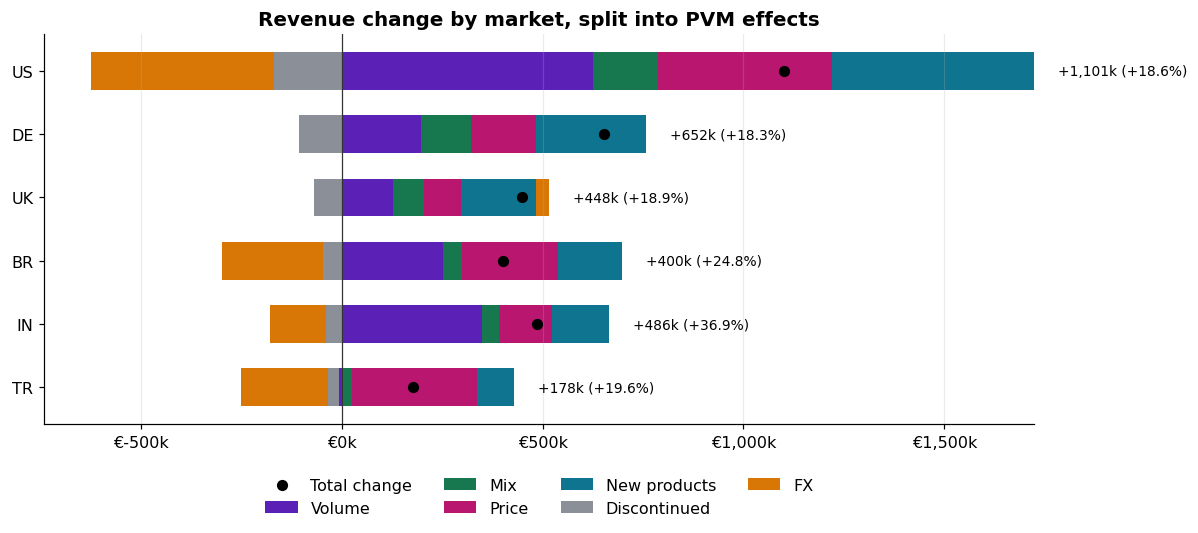

In [8]:
comp = ["Volume", "Mix", "Price", "New products", "Discontinued", "FX"]
fig, ax = plt.subplots(figsize=(11, 5))
y = np.arange(len(bm))
pos_left = np.zeros(len(bm)); neg_left = np.zeros(len(bm))
for cpt in comp:
    v = bm[cpt].values
    ax.barh(y, np.where(v > 0, v, 0), left=pos_left, color=COLORS[cpt], label=cpt, height=0.6)
    ax.barh(y, np.where(v < 0, v, 0), left=neg_left, color=COLORS[cpt], height=0.6)
    pos_left += np.where(v > 0, v, 0); neg_left += np.where(v < 0, v, 0)
ax.scatter(bm["Total change"], y, color="black", zorder=5, s=40, label="Total change")
for i, (tc, pct) in enumerate(zip(bm["Total change"], bm["Change %"])):
    ax.text(max(pos_left[i], 0) + bm["Start"].max() * 0.01, i, f"{tc/1e3:+,.0f}k ({pct:+.1%})", va="center", fontsize=9)
ax.axvline(0, color="#333", lw=0.8)
ax.set_yticks(y, bm.index); ax.invert_yaxis()
ax.xaxis.set_major_formatter(eur_k)
ax.set_title("Revenue change by market, split into PVM effects")
ax.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.1))
ax.grid(axis="y", visible=False)
fig.tight_layout(); plt.show()

Typical story here: **Turkey** has a big local price effect that is largely eaten by FX — in euros, the price increase did not keep up with the lira. **India** and **Brazil** grow on volume. A market can show a positive price effect and still shrink in euros.

## 6. Why granularity matters

Mix only exists *between the items you list*. If we measure PVM by product only, a shift from Web to Mobile (same product, lower net price) cannot be mix — it shows up as a **price** decline. At the SKU level the same shift is correctly reported as **mix**.

In [9]:
levels = {
    "product": ["product"],
    "market × product": ["market", "product"],
    "market × product × channel": ["market", "product", "channel"],
}
gran = pd.DataFrame({name: pvm(sales, k)["effects"] for name, k in levels.items()})
gran

,product,market × product,market × product × channel
Volume,"1,782,126.35","1,782,126.35","1,782,126.35"
Mix,"447,271.96","206,942.33","244,073.09"
Price,"1,164,203.21","1,404,532.84","1,367,402.08"
New products,"1,356,465.73","1,356,465.73","1,356,465.73"
Discontinued,"-452,035.58","-452,035.58","-452,035.58"
FX,"-1,032,021.34","-1,032,021.34","-1,032,021.34"


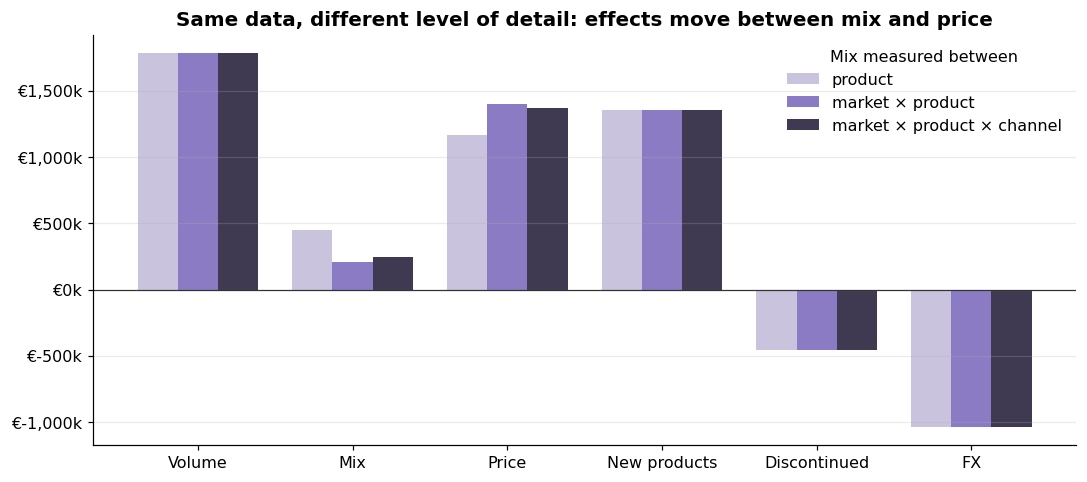

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(gran.index)); w = 0.26
shades = ["#C9C3DD", "#8B7BC4", "#3F3A52"]
for i, (col, sh) in enumerate(zip(gran.columns, shades)):
    ax.bar(x + (i - 1) * w, gran[col], w, label=col, color=sh)
ax.axhline(0, color="#333", lw=0.8)
ax.set_xticks(x, gran.index); ax.yaxis.set_major_formatter(eur_k)
ax.set_title("Same data, different level of detail: effects move between mix and price")
ax.legend(frameon=False, title="Mix measured between")
ax.grid(axis="x", visible=False)
fig.tight_layout(); plt.show()

Volume, new products, discontinued and FX barely change; **mix and price trade places**. Always state the level of detail, and pick the one that matches the decision — for pricing, usually market × product × channel (and term, if 1- and 2-year plans have different prices).

## 7. Biggest price contributors

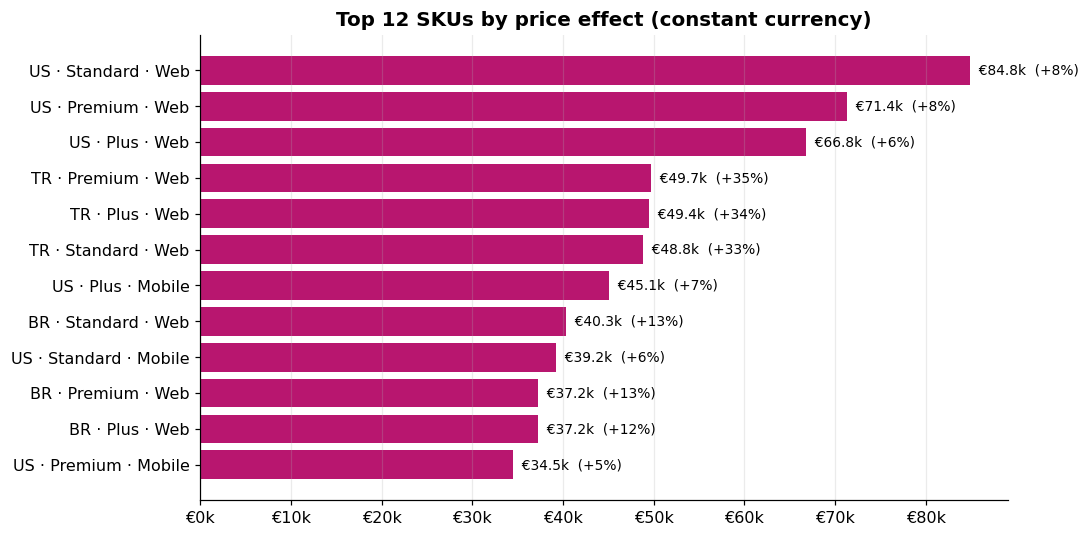

q0        q1    p0    p1  price_change_%  price_effect
market product  channel                                                              
US     Standard Web     40,341.00 38,500.00 27.97 30.18            0.08     84,842.59
       Premium  Web     15,499.00 17,965.00 52.27 56.24            0.08     71,360.97
       Plus     Web     23,962.00 27,329.00 40.21 42.66            0.06     66,804.22
TR     Premium  Web      4,638.00  5,476.00 26.27 35.35            0.35     49,742.42
       Plus     Web      7,285.00  7,349.00 20.07 26.80            0.34     49,441.97
       Standard Web     12,558.00 10,347.00 14.25 18.97            0.33     48,793.50
US     Plus     Mobile  13,826.00 20,126.00 33.94 36.18            0.07     45,097.15
BR     Standard Web     18,690.00 18,491.00 16.74 18.92            0.13     40,283.96
US     Standard Mobile  25,610.00 27,160.00 23.54 24.98            0.06     39,231.11
BR     Premium  Web      6,517.00  9,497.00 30.95 34.88            0.13     37,241.81

In [11]:
items = res["items"].copy()
items["price_effect"] = (items["p1"] - items["p0"]) * items["q1"]
items["price_change_%"] = items["p1"] / items["p0"] - 1
top = items.sort_values("price_effect", ascending=False).head(12)
top_lbl = [" · ".join(i) for i in top.index]

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(top_lbl, top["price_effect"], color=COLORS["Price"])
for i, (v, pc) in enumerate(zip(top["price_effect"], top["price_change_%"])):
    ax.text(v, i, f"  €{v/1e3:,.1f}k  ({pc:+.0%})", va="center", fontsize=9)
ax.invert_yaxis(); ax.xaxis.set_major_formatter(eur_k)
ax.set_title("Top 12 SKUs by price effect (constant currency)")
ax.grid(axis="y", visible=False)
fig.tight_layout(); plt.show()

items[["q0", "q1", "p0", "p1", "price_change_%", "price_effect"]].sort_values("price_effect", ascending=False).head(10)

## 8. Takeaways

- The bridge **reconciles exactly**: volume + mix + price + new + discontinued + FX = total change (the `assert` in `pvm` checks it).
- Use **net** prices and **constant currency** for the price effect; report FX separately, so local teams are judged on what they control.
- Keep **new and discontinued** products out of volume, mix and price.
- State the **level of detail**: it decides what counts as mix vs price.
- PVM is **attribution, not causality**: if a price increase reduced volume, PVM shows a positive price effect and a negative volume effect. To judge the decision itself, compare with a control market or use an elasticity model.

**Try it yourself:** change `price_increase`, `vol_growth` or the channel `unit_change` in section 1 and rerun — the charts show how each assumption flows into the bridge.